# 05 · How does acceptance respond to pay?

**Question.** If we offer a driver 10% more for a trip, how much more likely are they to accept
it, and does that differ by zone group and time of day? This curve is what the pay policy
(phase 6) optimizes over.

**Real and simulated.** The trips, their pay floor, the pay actually offered and the rider fare are
real (July–December 2024, the 0.5% sample). Whether the first driver accepted is **simulated**
with a planted truth (`ridepay/simulate.py`), because the public records don't contain it. The
planted truth is what makes this a fair test of the methods: we know the right answer.

**The trap.** In the history, the premium above the floor is highest on short trips and at night,
the trips drivers like least (phase 1). So in the history, extra pay arrives together with extra
difficulty, and a naive model credits pay with far less than it does. Pay is **confounded** with how
hard the trip is.

**Three ways to estimate the effect, side by side**
1. **Naive**: acceptance on pay, nothing else.
2. **Double machine learning (DML)**: remove from both acceptance and pay what the trip's features
   predict (with flexible models, cross-fitted), then relate what's left. Valid if every feature
   that drives both pay and acceptance is observed.
3. **The randomized pay test**: for four months, 8% of offers were moved by a random ±15% (never
   below the floor). Randomization breaks the link to difficulty, so it needs no assumption about
   features; it is used as the **check** on DML, not as the main estimate (8% of four months is
   small and only covers ±15%).

Then a **Bayesian hierarchical model** gives the curve for each segment (zone cluster × hour
band) with uncertainty, pooling small segments toward the average.

In [1]:
import time

import arviz as az
import lightgbm as lgb
import numpy as np
import pandas as pd

from ridepay import accept, data, features, plots, simulate
from ridepay.records import show_verdict, write_metrics

SOURCE = data.source()
FAST = SOURCE != "real"          # CI smoke run on the synthetic city: smaller samples, shorter chains
con = data.connect()
ALL = data.months()
MONTHS = [m for m in ALL if "2024-07" <= m <= "2024-12"] or ALL[:6]
TEST_MONTHS = MONTHS[-4:]
trips, info = features.trip_frame(MONTHS, con)
feats = simulate.difficulty_features(trips, info)
cluster_wait = (con.sql("""SELECT zone, SUM(wait_sum_sec)/SUM(wait_n)/60 AS w FROM zone_hour GROUP BY 1""").df()
                .set_index("zone")["w"].groupby(info["cluster_name"]).mean().to_dict())
print(f"{len(trips):,} real trips, {MONTHS[0]} to {MONTHS[-1]}; pay test in {TEST_MONTHS}")

593,901 real trips, 2024-07 to 2024-12; pay test in ['2024-09', '2024-10', '2024-11', '2024-12']


## Plant the truth and simulate

Each segment gets a true intercept (calibrated so today's acceptance hits a target that is lower
where real waits are longer) and a true pay sensitivity β (log-odds per unit of log pay; β = 4 means
a 10% higher offer adds 0.38 to the log-odds).

In [2]:
truth = simulate.make_truth(trips, feats, cluster_wait)
sim = simulate.simulate(trips, feats, truth, TEST_MONTHS)
truth_table = truth.to_frame()
truth_table["trips"] = sim.groupby(["cluster_name", "band"]).size()
truth_table["acceptance_sim"] = sim.groupby(["cluster_name", "band"])["accept"].mean()
print(f"first-offer acceptance overall: {sim['accept'].mean():.3f}; pay-test trips: {int(sim['in_test'].sum()):,}")
truth_table.round(3)

first-offer acceptance overall: 0.723; pay-test trips: 31,968


a   beta  target_acceptance  trips  \
cluster_name         band                                              
Airports             am_peak -0.007  5.908              0.500   2720   
                     evening  0.365  6.416              0.500   6127   
                     midday  -0.018  5.727              0.500   6788   
                     night    0.687  6.833              0.500   1937   
                     pm_peak  0.111  5.715              0.500   5404   
Commuter residential am_peak  1.084  3.485              0.730  56445   
                     evening  1.013  3.699              0.730  46501   
                     midday   1.052  3.144              0.730  77590   
                     night    1.073  4.835              0.680  31488   
                     pm_peak  1.075  3.054              0.730  57960   
Core                 am_peak  0.977  4.237              0.748  39771   
                     evening  0.944  3.413              0.748  71202   
                     midday   0.997  3.338              0.748  75013   
                     night    0.976  4.365              0.698  43188   
                     pm_peak  1.021  3.488              0.748  68324   
Long waits           am_peak  0.838  4.084              0.653    383   
                     evening  0.789  4.027              0.653    805   
                     midday   0.740  3.288              0.653    940   
                     night    0.841  4.690              0.603    342   
                     pm_peak  0.739  4.175              0.653    973   

                              acceptance_sim  
cluster_name         band                     
Airports             am_peak           0.508  
                     evening           0.502  
                     midday            0.496  
                     night             0.488  
                     pm_peak           0.499  
Commuter residential am_peak           0.730  
                     evening           0.729  
                     midday            0.730  
                     night             0.683  
                     pm_peak           0.729  
Core                 am_peak           0.749  
                     evening           0.745  
                     midday            0.749  
                     night             0.699  
                     pm_peak           0.748  
Long waits           am_peak           0.668  
                     evening           0.627  
                     midday            0.654  
                     night             0.605  
                     pm_peak           0.626

## What the history shows

,trips,acceptance,short_share,night_share
premium_bin,,,,
at floor,313966,0.676,0.252,0.127
+1–10%,80043,0.700,0.277,0.119
+10–30%,86977,0.757,0.377,0.138
+30–60%,40664,0.839,0.599,0.130
+60%+,40229,0.934,0.773,0.153


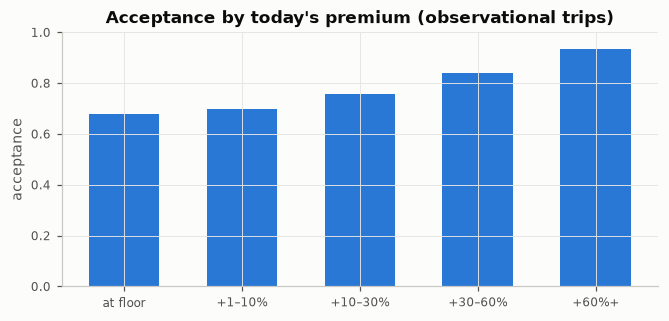

In [3]:
sim["premium_bin"] = pd.cut(sim["offer_sq"] / sim["floor"], [0.999, 1.01, 1.1, 1.3, 1.6, 10],
                            labels=["at floor", "+1–10%", "+10–30%", "+30–60%", "+60%+"])
obs = sim[~sim["in_test"]].groupby("premium_bin", observed=True).agg(
    trips=("accept", "size"), acceptance=("accept", "mean"), short_share=("trip_miles", lambda m: (m < 2).mean()),
    night_share=("band", lambda b: (b == "night").mean()))
fig, ax = plots.subplots(figsize=(7, 3))
ax.bar(obs.index.astype(str), obs["acceptance"], color=plots.SERIES[0], width=0.6)
ax.set(title="Acceptance by today's premium (observational trips)", ylabel="acceptance", ylim=(0, 1))
data.savefig(fig, "05_naive_view")
obs.round(3)

Acceptance rises with the premium, but the high-premium trips are mostly **short** trips, which
drivers dislike: part of what pay buys is spent overcoming that. Reading the slope off this table
mixes the effect of pay with the effect of difficulty, and understates what pay does.

## Estimates of the average effect

All three methods estimate a slope on the **probability** scale (acceptance per unit of log pay;
the last column converts to percentage points per 10% more pay). With a non-linear truth, each
method averages trip-level effects with its own weights: DML weights trips by how much their pay
differs from what their features predict, the pay test by how much the random shock moved their
pay. So for each method we compute the true value of *its own* estimand from the planted model
(holding each trip's unobserved difficulty fixed); for the naive slope the comparison is the true
average effect.

In [4]:
X_COLS = ["trip_miles", "minutes", "hod", "dow", "prev_wait_min", "deadhead", "is_airport", "shared_request",
          "cluster", "PULocationID"]
obsd = sim.assign(deadhead=feats["deadhead"], cluster=sim["cluster_name"].astype("category").cat.codes,
                  is_airport=sim["is_airport"].astype(int), shared_request=sim["shared_request"].astype(int))
obs_mask = ~obsd["in_test"].to_numpy()
OBS = obsd[obs_mask]


def learner():
    return lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=63, min_child_samples=100,
                             subsample=0.8, subsample_freq=1, verbose=-1, n_jobs=2)


t0 = time.time()
naive = accept.naive_slope(OBS["accept"], OBS["log_ratio"])
dml, rt = accept.dml_plr(OBS["accept"], OBS["log_ratio"], OBS[X_COLS], learner, categorical=["PULocationID"])
T = obsd[obsd["in_test"]]
iv = accept.iv_wald(T["accept"], T["log_ratio"], T["s"])
ame_true_obs = float(OBS["tau_true"].mean())     # true average marginal effect: what naive *should* find
p_obs = OBS["p_true"].to_numpy()
p_pred = simulate.p_at(OBS, feats.loc[OBS.index], truth, OBS["log_ratio"].to_numpy() - rt)
estimates = pd.DataFrame([
    {"method": naive.name, "estimate": naive.theta, "lo": naive.ci[0], "hi": naive.ci[1],
     "truth_of_estimand": ame_true_obs, "n": len(OBS)},
    {"method": dml.name, "estimate": dml.theta, "lo": dml.ci[0], "hi": dml.ci[1],
     "truth_of_estimand": accept.true_dml(rt, p_obs, p_pred), "n": len(OBS)},
    {"method": iv.name, "estimate": iv.theta, "lo": iv.ci[0], "hi": iv.ci[1],
     "truth_of_estimand": accept.true_iv(T["log_ratio"], T["s"], T["p_true"]), "n": len(T)},
]).set_index("method")
estimates["covers_truth"] = (estimates["lo"] <= estimates["truth_of_estimand"]) & (estimates["truth_of_estimand"] <= estimates["hi"])
estimates["per_10pct_pay_pp"] = estimates["estimate"] * np.log(1.1) * 100
ame_true = float(obsd["tau_true"].mean())
print(f"true average marginal effect (all trips): {ame_true:.3f} per unit log pay = "
      f"{ame_true * np.log(1.1) * 100:.2f} pp per 10% more pay; {time.time() - t0:.0f}s")
estimates.round(4)

true average marginal effect (all trips): 0.659 per unit log pay = 6.28 pp per 10% more pay; 63s


,estimate,lo,hi,truth_of_estimand,n,covers_truth,per_10pct_pay_pp
method,,,,,,,
Naive (no controls),0.3309,0.3273,0.3345,0.6605,561933,False,3.1539
Double ML,0.4239,0.4184,0.4294,0.4256,561933,True,4.0401
Randomized pay test (IV),0.6627,0.5806,0.7448,0.5985,31968,True,6.3164


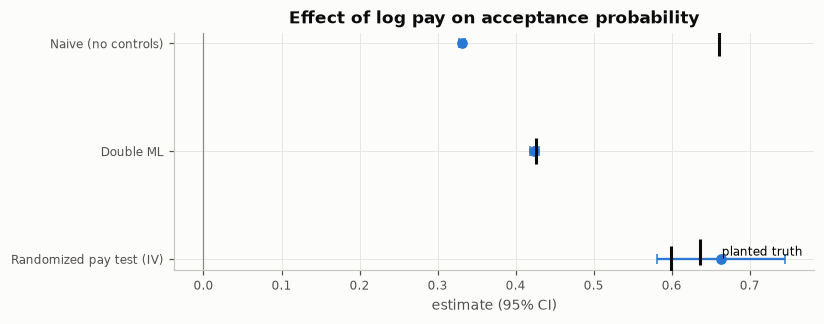

In [5]:
fig, ax = plots.subplots(figsize=(7.5, 2.8))
ypos = np.arange(len(estimates))[::-1]
ax.errorbar(estimates["estimate"], ypos, xerr=[estimates["estimate"] - estimates["lo"], estimates["hi"] - estimates["estimate"]],
            fmt="o", color=plots.SERIES[0], ms=6, capsize=3, lw=1.5)
ax.scatter(estimates["truth_of_estimand"], ypos, marker="|", s=300, color=plots.INK, zorder=3, label="planted truth")
ax.axvline(0, color=plots.GREY, lw=0.8)
ax.set_yticks(ypos, estimates.index)
ax.set(title="Effect of log pay on acceptance probability", xlabel="estimate (95% CI)")
ax.legend(loc="lower right")
data.savefig(fig, "05_estimates")

## When DML fails: a confounder we can't see

DML adjusts only for what is observed. Suppose operations also raise pay in reaction to something
missing from the data (a road closure the analyst can't see). Re-simulate with the unobserved part
of difficulty correlated with the premium and re-run both checks.

In [6]:
sim_h = simulate.simulate(trips, feats, truth, TEST_MONTHS, hidden_confounding=0.6)
Oh = sim_h[obs_mask].assign(deadhead=feats["deadhead"][obs_mask], cluster=OBS["cluster"],
                            is_airport=OBS["is_airport"], shared_request=OBS["shared_request"])
dml_h, rt_h = accept.dml_plr(Oh["accept"], Oh["log_ratio"], Oh[X_COLS], learner, categorical=["PULocationID"])
Th = sim_h[sim_h["in_test"]]
iv_h = accept.iv_wald(Th["accept"], Th["log_ratio"], Th["s"])
ph_pred = simulate.p_at(Oh, feats.loc[Oh.index], truth, Oh["log_ratio"].to_numpy() - rt_h)
hidden = pd.DataFrame([
    {"method": "Double ML", "estimate": dml_h.theta, "lo": dml_h.ci[0], "hi": dml_h.ci[1],
     "truth_of_estimand": accept.true_dml(rt_h, Oh["p_true"].to_numpy(), ph_pred)},
    {"method": "Randomized pay test (IV)", "estimate": iv_h.theta, "lo": iv_h.ci[0], "hi": iv_h.ci[1],
     "truth_of_estimand": accept.true_iv(Th["log_ratio"], Th["s"], Th["p_true"])},
]).set_index("method")
hidden["covers_truth"] = (hidden["lo"] <= hidden["truth_of_estimand"]) & (hidden["truth_of_estimand"] <= hidden["hi"])
hidden.round(4)

,estimate,lo,hi,truth_of_estimand,covers_truth
method,,,,,
Double ML,0.3197,0.3139,0.3254,0.5778,False
Randomized pay test (IV),0.6693,0.5867,0.7518,0.6175,True


**This is why the pay test exists.** With hidden confounding, DML is confidently wrong and nothing
inside the observational data reveals it. Only the randomized slice can: a model built on the
observational data predicts what the test should measure, and a mismatch is the alarm (the check
is run on the main model below). The decision rule: use the observational model for its precision
and segment detail **as long as it predicts the randomized test**; if not, trust the test and widen
the uncertainty.

## Segment curves: Bayesian hierarchical logistic model

Per segment g: `logit P = α_g + β_g · log(pay/floor) − γ · difficulty`. Each zone cluster has its own
mean slope and intercept; the hour bands within a cluster are **partially pooled** toward that mean,
with a spread learned from the data. (Pooling clusters toward a city mean as well was tried: with
only four clusters that spread is barely identified and the sampler slowed to a crawl, so cluster
means get a weakly informative prior instead.) Fitted on a subsample so that small
segments are genuinely small, which is when pooling matters. Difficulty features are the observed
ones (short trip, destination dead-heading, supply tightness); night needs no feature of its own,
since the night hour band is already a segment.

One subtlety: the unobserved part of difficulty (u) isn't in the model, and leaving out a random
term in a logistic model shrinks every coefficient slightly toward zero (about 4% here). The
fitted model describes acceptance *on average over u*, which is the curve a pay policy needs.

In [7]:
segments = sorted(truth.beta)
seg_index = {s: i for i, s in enumerate(segments)}
fitdf = obsd.join(feats[["short", "tight"]])
fitdf["seg"] = [seg_index[(c, b)] for c, b in zip(fitdf["cluster_name"], fitdf["band"])]
rng = np.random.default_rng(3)
sub = fitdf.iloc[rng.choice(len(fitdf), size=min(8_000 if FAST else 40_000, len(fitdf)), replace=False)]
t0 = time.time()
model, idata = accept.fit_hierarchical(sub, segments, draws=200 if FAST else 1000, tune=300 if FAST else 1000, chains=2)
HYPER = ["mu_beta", "sigma_beta", "mu_alpha", "sigma_alpha"]
summ = az.summary(idata, var_names=HYPER + ["beta", "alpha", "gamma"], round_to=4)
diag = {"max_rhat": float(summ["r_hat"].max()), "min_ess_bulk": float(summ["ess_bulk"].min()),
        "divergences": int(idata.sample_stats["diverging"].sum()), "seconds": round(time.time() - t0)}
print(diag)
summ.loc[[i for i in summ.index if i.split("[")[0] in HYPER or i.startswith("gamma")]]

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (2 chains in 2 jobs)


NUTS: [mu_beta, sigma_beta, z_beta, mu_alpha, sigma_alpha, z_alpha, gamma]


Sampling 2 chains for 1_000 tune and 1_000 draw iterations (2_000 + 2_000 draws total) took 278 seconds.


There was 1 divergence after tuning. Increase `target_accept` or reparameterize.


We recommend running at least 4 chains for robust computation of convergence diagnostics


{'max_rhat': 1.0074, 'min_ess_bulk': 580.1424, 'divergences': 1, 'seconds': 283}


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
mu_beta[Airports],5.3113,0.5937,4.3866,6.2968,3017.6903,1480.2792,1.0007,0.0108,0.0141
mu_beta[Commuter residential],3.3961,0.2439,3.0297,3.7926,1449.7526,1210.2299,1.0008,0.0068,0.0089
mu_beta[Core],3.6535,0.2322,3.3154,4.0318,1319.0995,769.7601,1.0035,0.0069,0.0087
mu_beta[Long waits],4.4903,0.9599,2.9871,6.0877,2369.1095,1436.3857,1.0019,0.0199,0.0243
sigma_beta,0.3708,0.2026,0.0780,0.7128,580.1424,675.4496,1.0074,0.0081,0.0062
mu_alpha[Airports],0.1640,0.0914,0.0258,0.3183,1428.1468,1359.0492,1.0001,0.0025,0.0022
mu_alpha[Commuter residential],0.9469,0.0708,0.8386,1.0577,877.1120,995.3621,1.0004,0.0024,0.0022
mu_alpha[Core],0.8568,0.0678,0.7503,0.9592,858.0887,1022.6475,1.0008,0.0023,0.0019
mu_alpha[Long waits],0.4054,0.1770,0.1292,0.6829,3077.8431,1640.8011,1.0009,0.0032,0.0049
sigma_alpha,0.1401,0.0412,0.0858,0.2127,978.0851,1244.3867,0.9997,0.0013,0.0012


**No pooling vs partial pooling.** For comparison, a separate logistic regression per segment on the
same subsample. Small segments get noisy, sometimes absurd slopes on their own; the hierarchical model
pulls them toward the average by an amount the data decides.

In [8]:
import warnings  # noqa: E402

import statsmodels.api as sm  # noqa: E402
from statsmodels.tools.sm_exceptions import ConvergenceWarning  # noqa: E402

post_beta = accept._posterior(idata)["beta"].stack(s=("chain", "draw")).transpose("seg", "s").to_numpy()
rows = []
for seg, i in seg_index.items():
    d = sub[sub["seg"] == i]
    try:
        Xs = sm.add_constant(np.c_[d["log_ratio"], -d[accept.FEATURES].to_numpy()])
        with warnings.catch_warnings():   # tiny segments often don't converge: that is the point of the comparison
            warnings.simplefilter("ignore", ConvergenceWarning)
            nopool = sm.Logit(d["accept"], Xs).fit(disp=0).params.iloc[1] if len(d) >= 30 else np.nan
    except Exception:  # perfect separation or singular design in a tiny segment
        nopool = np.nan
    lo, hi = np.percentile(post_beta[i], [5, 95])
    rows.append({"cluster": seg[0], "band": seg[1], "n": len(d), "beta_true": truth.beta[seg],
                 "beta_no_pool": nopool, "beta_hier": post_beta[i].mean(), "lo90": lo, "hi90": hi})
seg_table = pd.DataFrame(rows)
seg_table["covered90"] = (seg_table["lo90"] <= seg_table["beta_true"]) & (seg_table["beta_true"] <= seg_table["hi90"])
attn = 1 / np.sqrt(1 + 0.346 * simulate.U_SD**2)   # approx. logit attenuation from an omitted normal term
rmse = {"no_pool": float(np.sqrt(np.nanmean((seg_table["beta_no_pool"] - seg_table["beta_true"] * attn) ** 2))),
        "hierarchical": float(np.sqrt(np.mean((seg_table["beta_hier"] - seg_table["beta_true"] * attn) ** 2)))}
print(f"RMSE of segment slopes vs truth (attenuation-adjusted ×{attn:.3f}): {rmse}; "
      f"90% intervals cover the truth in {seg_table['covered90'].mean():.0%} of segments")
seg_table.round(3)

RMSE of segment slopes vs truth (attenuation-adjusted ×0.959): {'no_pool': 1.9006175747239316, 'hierarchical': 0.5645693654402303}; 90% intervals cover the truth in 90% of segments


,cluster,band,n,beta_true,beta_no_pool,beta_hier,lo90,hi90,covered90
0,Airports,am_peak,193,5.908,3.610,5.192,4.044,6.322,True
1,Airports,evening,384,6.416,6.982,5.548,4.511,6.706,True
2,Airports,midday,486,5.727,4.144,5.087,4.002,6.175,True
3,Airports,night,123,6.833,6.413,5.406,4.349,6.541,False
4,Airports,pm_peak,370,5.715,8.237,5.416,4.363,6.522,True
5,Commuter residential,am_peak,3858,3.485,3.522,3.480,3.089,3.896,True
6,Commuter residential,evening,3035,3.699,3.473,3.333,2.911,3.745,True
7,Commuter residential,midday,5215,3.144,3.302,3.334,2.938,3.715,True
8,Commuter residential,night,2079,4.835,4.573,3.651,3.194,4.182,False
9,Commuter residential,pm_peak,3887,3.054,3.087,3.200,2.751,3.614,True


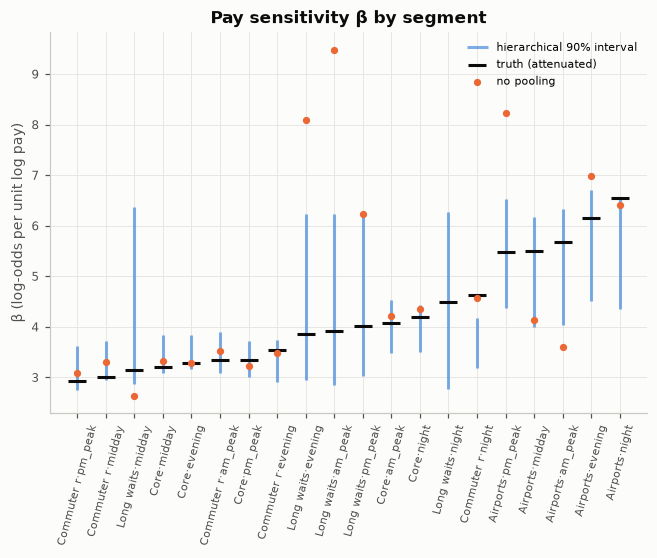

In [9]:
fig, ax = plots.subplots(figsize=(7, 4.5))
o = seg_table.sort_values("beta_true").reset_index(drop=True)
ax.vlines(o.index, o["lo90"], o["hi90"], color=plots.SERIES[0], lw=2, alpha=0.6, label="hierarchical 90% interval")
ax.scatter(o.index, o["beta_true"] * attn, color=plots.INK, marker="_", s=150, zorder=3, label="truth (attenuated)")
ax.scatter(o.index, o["beta_no_pool"].clip(-5, 15), color=plots.SERIES[1], s=14, zorder=3, label="no pooling")
ax.set_xticks(o.index, [f"{c[:10]}·{b}" for c, b in zip(o["cluster"], o["band"])], rotation=75, fontsize=7)
ax.set(title="Pay sensitivity β by segment", ylabel="β (log-odds per unit log pay)")
ax.legend(fontsize=7)
data.savefig(fig, "05_segment_slopes")

**Posterior predictive check**: simulate acceptance from the fitted model and compare with the
observed rate by decile of predicted probability on trips *not* in the fitting subsample.

In [10]:
draws = accept.posterior_draws(idata, n=200)
held = fitdf.drop(sub.index).sample(min(100_000, len(fitdf) - len(sub)), random_state=1)
F = held[accept.FEATURES].to_numpy()
pm_mean = np.mean([accept.predict_accept(draws["alpha"][k], draws["beta"][k], draws["gamma"][k],
                                          held["seg"].to_numpy(), held["log_ratio"].to_numpy(), F)
                   for k in range(0, 200, 10)], axis=0)
dec = pd.qcut(pm_mean, 10, duplicates="drop")
ppc = pd.DataFrame({"predicted": pm_mean, "observed": held["accept"].to_numpy()}).groupby(dec, observed=True).mean()
ppc_gap = float((ppc["predicted"] - ppc["observed"]).abs().max())
print(f"largest decile gap, predicted vs observed acceptance on held-out trips: {ppc_gap:.3f}")
ppc.round(3)

largest decile gap, predicted vs observed acceptance on held-out trips: 0.006


,predicted,observed
"(0.154, 0.583]",0.493,0.494
"(0.583, 0.646]",0.618,0.622
"(0.646, 0.682]",0.665,0.666
"(0.682, 0.707]",0.695,0.699
"(0.707, 0.727]",0.717,0.724
"(0.727, 0.744]",0.736,0.739
"(0.744, 0.764]",0.753,0.754
"(0.764, 0.797]",0.778,0.780
"(0.797, 0.866]",0.827,0.822
"(0.866, 1.0]",0.928,0.926


**The check that matters: does the model predict what the pay test measured?** DML, the test and the
hierarchical model each average the effect of pay differently, so comparing their numbers directly
is apples to oranges. The fair check: feed the test's trips, with their randomized offers, through
the fitted model, compute the *same* IV statistic on the model's predicted acceptance, and compare it
with what the test actually measured.

In [11]:
Tt = fitdf[fitdf["in_test"]]
FT = Tt[accept.FEATURES].to_numpy()
model_iv = np.array([accept.true_iv(Tt["log_ratio"], Tt["s"],
                                    accept.predict_accept(draws["alpha"][k], draws["beta"][k], draws["gamma"][k],
                                                          Tt["seg"].to_numpy(), Tt["log_ratio"].to_numpy(), FT))
                     for k in range(len(draws["beta"]))])
model_check = {"model_implied_iv": float(model_iv.mean()), "model_lo90": float(np.percentile(model_iv, 5)),
               "model_hi90": float(np.percentile(model_iv, 95)), "test_iv": iv.theta, "test_lo": iv.ci[0], "test_hi": iv.ci[1]}
model_check["agree"] = bool(model_check["model_hi90"] >= iv.ci[0] and model_check["model_lo90"] <= iv.ci[1])
print({k: round(v, 4) if isinstance(v, float) else v for k, v in model_check.items()})

{'model_implied_iv': 0.6042, 'model_lo90': 0.5807, 'model_hi90': 0.6276, 'test_iv': 0.6627, 'test_lo': 0.5806, 'test_hi': 0.7448, 'agree': True}


In [12]:
np.savez(data.interim_dir() / "derived" / "accept_posterior.npz", alpha=draws["alpha"], beta=draws["beta"],
         gamma=draws["gamma"], segments=np.array([f"{a}|{b}" for a, b in segments]))
truth_out = truth.to_frame().reset_index()
_ = data.save_table(truth_out, "accept_truth")
record = {
    "months": MONTHS, "test_months": TEST_MONTHS, "n_trips": len(sim), "n_test": int(sim["in_test"].sum()),
    "acceptance": float(sim["accept"].mean()), "ame_true": ame_true,
    "estimates": estimates.reset_index().to_dict(orient="records"), "model_vs_test": model_check,
    "hidden_confounding": hidden.reset_index().to_dict(orient="records"),
    "hierarchical": {"diagnostics": diag, "rmse": rmse, "coverage90": float(seg_table["covered90"].mean()),
                     "attenuation": attn, "hyper": summ.loc[[i for i in summ.index if i.split("[")[0] in HYPER], ["mean", "sd", "r_hat"]].to_dict(orient="index"),
                     "ppc_max_decile_gap": ppc_gap,
                     "segments": seg_table.round(4).to_dict(orient="records")},
    "truth": truth_out.round(4).to_dict(orient="records"),
}
_ = write_metrics("05_pay_to_accept", record, SOURCE)

## Verdict

In [13]:
E = estimates
pp = lambda v: v * np.log(1.1) * 100  # noqa: E731  percentage points per 10% more pay
show_verdict(
    "Verdict: phase 5, pay-to-accept",
    [
        f"**The naive reading badly understates pay.** Acceptance on pay alone gives {pp(E.loc[naive.name, 'estimate']):+.1f} pp "
        f"per 10% more pay; the true average effect is {pp(E.loc[naive.name, 'truth_of_estimand']):+.1f} pp. Premiums go to "
        "the trips drivers like least, so the history credits pay with "
        f"{E.loc[naive.name, 'estimate'] / E.loc[naive.name, 'truth_of_estimand']:.0%} of what it does.",
        f"**DML {'recovers' if E.loc[dml.name, 'covers_truth'] else 'comes close to'} its estimand**: {pp(dml.theta):+.2f} pp per "
        f"10% (95% CI {pp(dml.ci[0]):+.2f} to {pp(dml.ci[1]):+.2f}; truth {pp(E.loc[dml.name, 'truth_of_estimand']):+.2f}), and "
        f"**the randomized test {'agrees with the truth' if E.loc[iv.name, 'covers_truth'] else 'misses'}**: {pp(iv.theta):+.2f} pp "
        f"(CI {pp(iv.ci[0]):+.2f} to {pp(iv.ci[1]):+.2f}; truth {pp(E.loc[iv.name, 'truth_of_estimand']):+.2f}), with a CI "
        f"{(iv.ci[1] - iv.ci[0]) / (dml.ci[1] - dml.ci[0]):.0f}× wider. They estimate different averages (DML weights "
        "trips by unexplained pay variation, the test by its ±15% shocks), so the numbers differ even when both are right.",
        f"**The model passes the pay-test check**: fed the test's randomized offers, the hierarchical model predicts the "
        f"test would measure {pp(model_check['model_implied_iv']):+.2f} pp per 10% (90% {pp(model_check['model_lo90']):+.2f} to "
        f"{pp(model_check['model_hi90']):+.2f}); the test measured {pp(iv.theta):+.2f}." if model_check["agree"] else
        f"**The model FAILS the pay-test check**: it predicts {pp(model_check['model_implied_iv']):+.2f} pp per 10% where the "
        f"test measured {pp(iv.theta):+.2f}; trust the test and widen the policy's uncertainty.",
        f"**When a confounder is hidden, DML fails and the test catches it**: DML {pp(dml_h.theta):+.2f} pp vs its truth "
        f"{pp(hidden.loc['Double ML', 'truth_of_estimand']):+.2f} ({'covered' if hidden.loc['Double ML', 'covers_truth'] else 'not covered'}); "
        f"the randomized test {pp(iv_h.theta):+.2f} ({'covers' if hidden.loc['Randomized pay test (IV)', 'covers_truth'] else 'misses'} its truth).",
        f"**Segment curves with honest uncertainty**: the hierarchical model's slopes are closer to the truth than "
        f"separate per-segment fits (RMSE {rmse['hierarchical']:.2f} vs {rmse['no_pool']:.2f}); 90% intervals cover the "
        f"truth in {seg_table['covered90'].mean():.0%} of {len(seg_table)} segments; R̂ max {diag['max_rhat']:.3f}, "
        f"min ESS {diag['min_ess_bulk']:.0f}, {diag['divergences']} divergence{'' if diag['divergences'] == 1 else 's'}; held-out calibration within "
        f"{ppc_gap * 100:.1f} points.",
    ],
    "phase 6: use these curves to choose pay per trip, under the five constraints, and test it in a dispatch simulation.",
)

### Verdict: phase 5, pay-to-accept

1. **The naive reading badly understates pay.** Acceptance on pay alone gives +3.2 pp per 10% more pay; the true average effect is +6.3 pp. Premiums go to the trips drivers like least, so the history credits pay with 50% of what it does.
2. **DML recovers its estimand**: +4.04 pp per 10% (95% CI +3.99 to +4.09; truth +4.06), and **the randomized test agrees with the truth**: +6.32 pp (CI +5.53 to +7.10; truth +5.70), with a CI 15× wider. They estimate different averages (DML weights trips by unexplained pay variation, the test by its ±15% shocks), so the numbers differ even when both are right.
3. **The model passes the pay-test check**: fed the test's randomized offers, the hierarchical model predicts the test would measure +5.76 pp per 10% (90% +5.53 to +5.98); the test measured +6.32.
4. **When a confounder is hidden, DML fails and the test catches it**: DML +3.05 pp vs its truth +5.51 (not covered); the randomized test +6.38 (covers its truth).
5. **Segment curves with honest uncertainty**: the hierarchical model's slopes are closer to the truth than separate per-segment fits (RMSE 0.56 vs 1.90); 90% intervals cover the truth in 90% of 20 segments; R̂ max 1.007, min ESS 580, 1 divergence; held-out calibration within 0.6 points.

**Next:** phase 6: use these curves to choose pay per trip, under the five constraints, and test it in a dispatch simulation.